# 1. The sphere
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sap6/MFS/blob/main/notebooks/1_sphere.ipynb)

**Notebooks:** **1. Sphere** · [2. Torus](2_torus.ipynb) · [3. Cube](3_cube.ipynb) · [4. NASA almond](4_almond.ipynb)

We begin by focusing on the familiar domain of the unit sphere, for which the Mie series gives the exact scattered field (Section 3.1 of the paper). A plane wave impinges from the positive $z$-axis, polarised along $y$, with $k = 2\pi$, so the sphere is two wavelengths across.

The MFS approximates the scattered field by $N$ electric dipoles on an interior sphere of radius $R_s < 1$,
$$\mathbf{E}_N(\mathbf{x}) = \sum_{j=1}^N \mathbf{G}(\mathbf{x}, \mathbf{y}_j)\, \boldsymbol{\alpha}_j,$$
and chooses the coefficients so that the tangential part of the total field vanishes, in the least-squares sense, at $M = 2N$ boundary points on the unit sphere.

In [1]:
# Set up paths (and get the code and the data when run on Colab)
import os, subprocess, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/MFS"):
        subprocess.run(["git", "clone", "-q", "https://github.com/sap6/MFS", "/content/MFS"], check=True)
    os.chdir("/content/MFS/notebooks")            # numpy, scipy, numba and matplotlib come with Colab
elif os.path.isdir("notebooks") and os.path.isdir("mfs"):
    os.chdir("notebooks")
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mfs import core, mie, sphere

k = 2 * np.pi                  # wavenumber: the sphere is two wavelengths across
d, p = core.wave()             # propagation direction (0, 0, -1) and polarisation (0, 1, 0)

## One solve in five lines
Here is the entire method (`mfs/sphere.py`): Fibonacci lattices for boundary and source points, the $2M \times 3N$ matrix of tangential dipole fields, and a QR least-squares solve.

In [3]:
N, M, R = 400, 800, 0.5                                                     # 400 dipoles (1200 unknowns), 800 boundary points (1600 equations)
x, y = core.fibonacci(M), R * core.fibonacci(N)                             # boundary points on r = 1, sources on r = R
T = core.tangent_basis(x)                                                   # two unit tangents at each boundary point, (M, 2, 3)
A = np.einsum("mab,mnbc->manc", T, core.dyadic(x, y, k)).reshape(2 * M, 3 * N)
b = -np.einsum("mab,mb->ma", T, core.plane_wave(x, k, d, p)).reshape(-1)
alpha = core.QR(A).solve(b).reshape(N, 3)                                   # identical to sphere.solve(N, k, R=R)

# Compare with the Mie series on the sphere of radius 2
pts = 2.0 * core.fibonacci(400)
E_mfs = core.field(pts, y, alpha, k)
E_mie = mie.scattered_field(pts, k, d, p)
print(f"relative error against Mie: {core.rel(E_mfs, E_mie):.1e}  (coefficient norm ||alpha|| = {np.linalg.norm(alpha):.2f})")

relative error against Mie: 2.0e-09  (coefficient norm ||alpha|| = 13.27)


## Root-exponential convergence and the choice of $R_s$
Plotted against $\sqrt{N}$, the errors lie on straight lines, so the error decays like $\exp(-c\sqrt{N})$ (Figure 1 of the paper). Every source radius $R_s < 1$ encloses the singularity at the origin, so every radius converges, but placing sources too deep makes the columns of $A$ nearly dependent: the coefficient norm $\|\boldsymbol{\alpha}\|$ grows by orders of magnitude and cancellation limits the achievable accuracy.

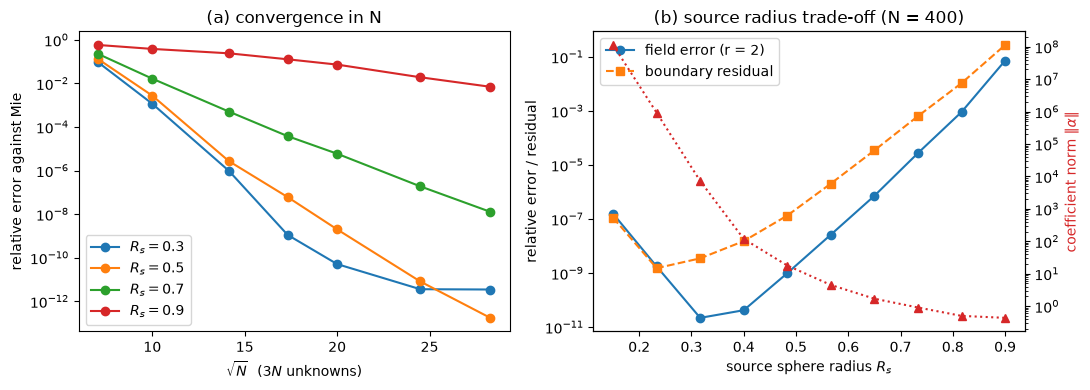

In [4]:
Ns = [50, 100, 200, 300, 400, 600, 800]
radii = np.linspace(0.15, 0.9, 10)
xt = core.fibonacci(600)
Tt = core.tangent_basis(xt)
inc_t = -np.einsum("mab,mb->ma", Tt, core.plane_wave(xt, k, d, p))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for R_s in (0.3, 0.5, 0.7, 0.9):
    err = [core.rel(core.field(pts, *sphere.solve(n, k, R_s), k), E_mie) for n in Ns]
    ax1.semilogy(np.sqrt(Ns), err, "o-", label=f"$R_s = {R_s}$")
ax1.set(xlabel=r"$\sqrt{N}$  ($3N$ unknowns)", ylabel="relative error against Mie", title="(a) convergence in N")
ax1.legend()

errs, resids, norms = [], [], []
for R_s in radii:
    ys, al = sphere.solve(400, k, R_s)
    errs.append(core.rel(core.field(pts, ys, al, k), E_mie))
    resids.append(core.rel(np.einsum("mab,mb->ma", Tt, core.field(xt, ys, al, k)), inc_t))
    norms.append(np.linalg.norm(al))
ax2.semilogy(radii, errs, "o-", label="field error (r = 2)")
ax2.semilogy(radii, resids, "s--", label="boundary residual")
ax2r = ax2.twinx()
ax2r.semilogy(radii, norms, "^:", color="tab:red", label=r"$\|\alpha\|$")
ax2.set(xlabel="source sphere radius $R_s$", ylabel="relative error / residual", title="(b) source radius trade-off (N = 400)")
ax2r.set_ylabel(r"coefficient norm $\|\alpha\|$", color="tab:red")
ax2.legend(loc="upper left")
fig.tight_layout()
plt.show()

## Smooth evaluation right up to the surface
Because the MFS approximation is a finite sum of interior dipole fields with no surface integrals, it is evaluated in the exact same way at every exterior point, even at a distance $10^{-4}$ from the conductor surface, where standard fixed-order boundary element quadrature loses accuracy (Figure 11 of the paper).

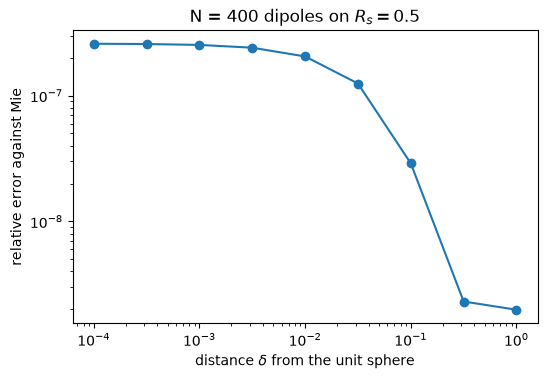

In [5]:
# Error on spheres of radius 1 + delta, from delta = 1e-4 up to 1
delta = np.logspace(-4, 0, 9)
err = [core.rel(core.field((1 + dl) * core.fibonacci(200), y, alpha, k),
                mie.scattered_field((1 + dl) * core.fibonacci(200), k, d, p)) for dl in delta]
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.loglog(delta, err, "o-")
ax.set(xlabel=r"distance $\delta$ from the unit sphere", ylabel="relative error against Mie",
       title="N = 400 dipoles on $R_s = 0.5$")
plt.show()